In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from backtester.data import load_prices

spy = load_prices('SPY', '2015-01-01', '2026-01-01')

Loaded SPY from cache: SPY_2015-01-01_2026-01-01.csv


In [9]:
spy.loc['2020-01-02'] # Access a specific date

Adj Close    2.953918e+02
Close        3.248700e+02
High         3.248900e+02
Low          3.225300e+02
Open         3.235400e+02
Volume       5.915120e+07
Name: 2020-01-02 00:00:00, dtype: float64

In [10]:
spy.loc['2020-01', 'Volume'] # Access a specific month and column

Date
2020-01-02     59151200
2020-01-03     77709700
2020-01-06     55653900
2020-01-07     40496400
2020-01-08     68296000
2020-01-09     48473300
2020-01-10     53029300
2020-01-13     47086800
2020-01-14     62832800
2020-01-15     72056600
2020-01-16     54050300
2020-01-17     95846000
2020-01-21     77742400
2020-01-22     48914900
2020-01-23     51963000
2020-01-24     87578400
2020-01-27     84062500
2020-01-28     63834000
2020-01-29     53888900
2020-01-30     75491800
2020-01-31    113845600
Name: Volume, dtype: int64

In [11]:
spy.loc['2020-01':'2020-06', ['Close', 'Adj Close']] # Access a range of dates and specific columns

,Close,Adj Close
Date,,
2020-01-02,324.869995,295.391785
2020-01-03,322.410004,293.154968
2020-01-06,323.640015,294.273438
2020-01-07,322.730011,293.445923
2020-01-08,324.450012,295.009979
...,...,...
2020-06-24,304.089996,279.347046
2020-06-25,307.350006,282.341827
2020-06-26,300.049988,275.635834


In [12]:
spy.iloc[0] # Access the first row

Adj Close    1.692675e+02
Close        2.054300e+02
High         2.068800e+02
Low          2.041800e+02
Open         2.063800e+02
Volume       1.214659e+08
Name: 2015-01-02 00:00:00, dtype: float64

In [13]:
spy.iloc[-1] # Access the last row

Adj Close    6.766350e+02
Close        6.819200e+02
High         6.873600e+02
Low          6.817100e+02
Open         6.871400e+02
Volume       7.414480e+07
Name: 2025-12-31 00:00:00, dtype: float64

In [14]:
spy.iloc[:5] # Access the first 5 rows

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2015-01-02,169.267487,205.429993,206.880005,204.179993,206.380005,121465900
2015-01-05,166.210632,201.720001,204.369995,201.350006,204.169998,169632600
2015-01-06,164.645035,199.820007,202.720001,198.860001,202.089996,209151400
2015-01-07,166.696732,202.309998,202.720001,200.880005,201.419998,125346700
2015-01-08,169.654739,205.899994,206.160004,203.990005,204.009995,147217800


In [17]:
spy.iloc[10:20] # Access rows from index 10 to 19

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2015-01-16,166.136475,201.630005,201.820007,198.550003,198.770004,211879600
2015-01-20,166.490753,202.059998,202.720001,200.169998,202.399994,130991100
2015-01-21,167.331192,203.080002,203.660004,200.940002,201.500000,122942700
2015-01-22,169.819595,206.100006,206.259995,202.330002,203.990005,174356000
2015-01-23,168.888458,204.970001,206.100006,204.809998,205.789993,117516800
2015-01-26,169.283997,205.449997,205.559998,203.850006,204.710007,92009700
2015-01-27,167.051056,202.740005,204.119995,201.740005,202.970001,134044600
2015-01-28,164.908752,200.139999,204.289993,199.910004,204.169998,168514300
2015-01-29,166.433060,201.990005,202.300003,198.679993,200.380005,173585400


In [18]:
spy.loc['2020-01-02':'2020-01-03'] # Access a range of dates

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2020-01-02,295.391785,324.869995,324.890015,322.529999,323.540009,59151200
2020-01-03,293.154968,322.410004,323.640015,321.100006,321.160004,77709700


In [19]:
prices = spy['Adj Close'].to_numpy() # Convert to numpy array

def double_with_loop(arr):
    result = []
    for p in arr:
        result.append(p * 2)
    return result

In [20]:
%timeit double_with_loop(prices)

212 μs ± 4.97 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [21]:
%timeit prices * 2

1.17 μs ± 10.9 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [25]:
prices > 500

array([False, False, False, ...,  True,  True,  True], shape=(2766,))

In [23]:
prices[prices > 500]

array([500.40438843, 500.91976929, 505.55303955, 507.22366333,
       506.262146  , 504.86334229, 503.93081665, 508.165802  ,
       508.06869507, 507.18481445, 503.96008301, 504.51367188,
       503.5617981 , 503.84341431, 504.42626953, 503.14413452,
       501.75512695, 502.30883789, 502.35733032, 505.25183105,
       505.90267944, 505.97064209, 508.29217529, 514.58636475,
       513.52746582, 514.26580811, 514.85821533, 516.12078857,
       514.63476562, 510.87582397, 514.25610352, 514.61529541,
       511.01184082, 507.62188721, 512.2454834 , 512.66308594,
       513.23614502, 519.33599854, 519.32641602, 518.69506836,
       520.29760742, 521.55078125, 525.83416748, 526.89294434,
       527.21350098, 531.40960693, 532.75964355, 531.3125    ,
       530.60003662, 528.87536621, 530.9119873 , 531.57458496,
       532.41253662, 530.31738281, 531.40887451, 534.98522949,
       537.37255859, 540.47131348, 541.09503174, 541.62115479,
       546.98059082, 542.26428223, 545.68457031, 547.18

In [31]:
(prices > 500).sum()

np.int64(429)

In [44]:
manual_returns = (spy["Adj Close"] / spy["Adj Close"].shift(1)) - 1
manual_returns

Date
2015-01-02         NaN
2015-01-05   -0.018059
2015-01-06   -0.009419
2015-01-07    0.012461
2015-01-08    0.017745
                ...   
2025-12-24    0.003518
2025-12-26   -0.000101
2025-12-29   -0.003564
2025-12-30   -0.001221
2025-12-31   -0.007409
Name: Adj Close, Length: 2766, dtype: float64

In [45]:
automatic_returns = spy["Adj Close"].pct_change()
automatic_returns

Date
2015-01-02         NaN
2015-01-05   -0.018059
2015-01-06   -0.009419
2015-01-07    0.012461
2015-01-08    0.017745
                ...   
2025-12-24    0.003518
2025-12-26   -0.000101
2025-12-29   -0.003564
2025-12-30   -0.001221
2025-12-31   -0.007409
Name: Adj Close, Length: 2766, dtype: float64

In [50]:
manual_automatic_comparison = (manual_returns - automatic_returns).abs().max()
manual_automatic_comparison

np.float64(0.0)

In [60]:
automatic_returns.idxmin(), f"{automatic_returns.min():.2%}"

(Timestamp('2020-03-16 00:00:00'), '-10.94%')

In [63]:
spy["Adj Close"].rolling(5).mean()

Date
2015-01-02           NaN
2015-01-05           NaN
2015-01-06           NaN
2015-01-07           NaN
2015-01-08    167.294925
                 ...    
2025-12-24    678.349048
2025-12-26    681.491113
2025-12-29    682.931848
2025-12-30    683.364465
2025-12-31    682.165833
Name: Adj Close, Length: 2766, dtype: float64

In [104]:
spy["SMA_5"] = spy["Adj Close"].rolling(5).mean()
spy["SMA_20"] = spy["Adj Close"].rolling(20).mean()
spy["SMA_50"] = spy["Adj Close"].rolling(50).mean()

In [69]:
spy["SMA_50"].isna().sum()

np.int64(49)

In [73]:
spy["Adj Close"].iloc[0:20].mean()

np.float64(166.92127151489257)

In [76]:
spy.iloc[19]["SMA_20"]

np.float64(166.92127151489257)

In [77]:
bhp = load_prices('BHP.AX', '2015-01-01', '2026-01-01')

[*********************100%***********************]  1 of 1 completed


In [78]:
len(bhp)

2785

In [79]:
len(spy)

2766

In [81]:
spy.index.difference(bhp.index)

DatetimeIndex(['2015-01-26', '2015-04-06', '2015-06-08', '2016-01-26',
               '2016-03-28', '2016-04-25', '2016-06-13', '2016-12-27',
               '2017-01-26', '2017-04-17', '2017-04-25', '2017-06-12',
               '2017-12-26', '2018-01-26', '2018-04-02', '2018-04-25',
               '2018-06-11', '2018-12-26', '2019-01-28', '2019-04-22',
               '2019-04-25', '2019-06-10', '2019-12-26', '2020-01-27',
               '2020-04-13', '2020-06-08', '2020-12-28', '2021-01-26',
               '2021-04-05', '2021-06-14', '2021-12-27', '2021-12-28',
               '2022-01-03', '2022-01-26', '2022-04-18', '2022-04-25',
               '2022-06-13', '2022-09-22', '2022-12-27', '2023-01-26',
               '2023-04-10', '2023-04-25', '2023-06-12', '2023-12-26',
               '2024-01-26', '2024-04-01', '2024-04-25', '2024-06-10',
               '2024-12-26', '2025-01-27', '2025-04-21', '2025-04-25',
               '2025-06-09', '2025-12-26'],
              dtype='datetime64[u

In [85]:
bhp_returns = bhp["Adj Close"].pct_change()
bhp_returns.idxmin(), f"{bhp_returns.min():.2%}"

(Timestamp('2020-03-09 00:00:00'), '-14.41%')

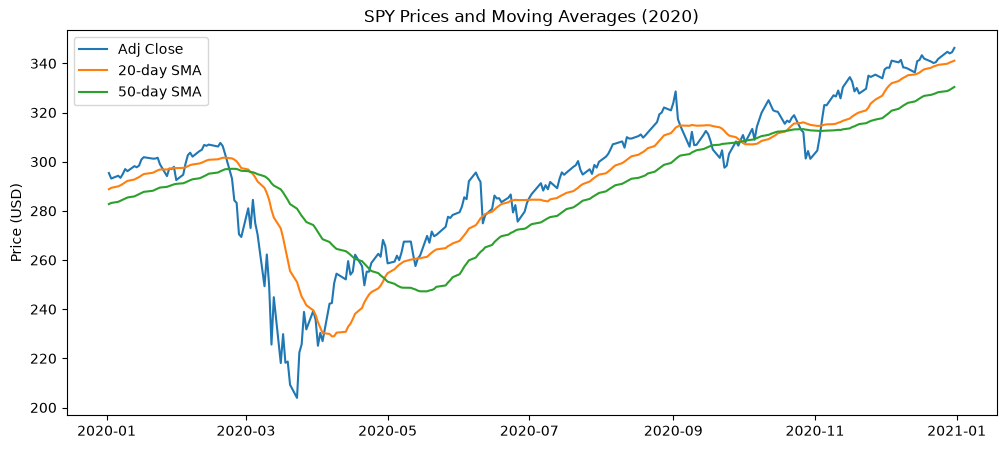

In [88]:
view = spy.loc["2020"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(view.index, view["Adj Close"], label="Adj Close")
ax.plot(view.index, view["SMA_20"], label="20-day SMA")
ax.plot(view.index, view["SMA_50"], label="50-day SMA")
ax.set_title("SPY Prices and Moving Averages (2020)")
ax.set_ylabel("Price (USD)")
ax.legend()
plt.show()

In [99]:
def plot_price_with_smas(df, title, currency="USD"):
    """Plot adjusted close with the 20-day and 50-day moving averages.

    Expects df to already have SMA_20 and SMA_50 columns. Add them before
    calling, or pandas will raise a KeyError. Pass a slice such as
    spy.loc["2020"] to plot a specific period.
    """
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(df.index, df["Adj Close"], label="Adj Close")
    ax.plot(df.index, df["SMA_20"], label="20-day SMA")
    ax.plot(df.index, df["SMA_50"], label="50-day SMA")
    ax.set_title(title)
    ax.set_ylabel(f"Price ({currency})")
    ax.legend()
    plt.show()

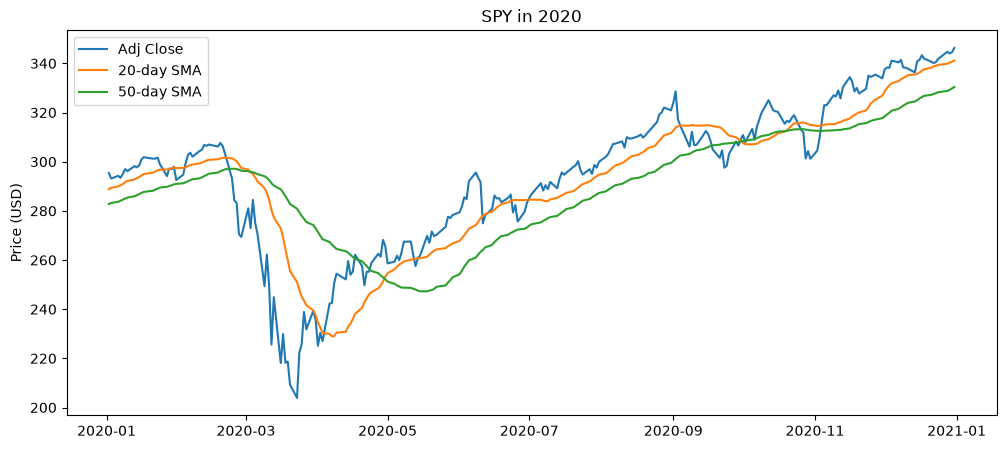

In [102]:
spy_price_and_smas = plot_price_with_smas(spy.loc["2020"], "SPY in 2020")
spy_price_and_smas

In [106]:
bhp["SMA_5"] = bhp["Adj Close"].rolling(5).mean()
bhp["SMA_20"] = bhp["Adj Close"].rolling(20).mean()
bhp["SMA_50"] = bhp["Adj Close"].rolling(50).mean()

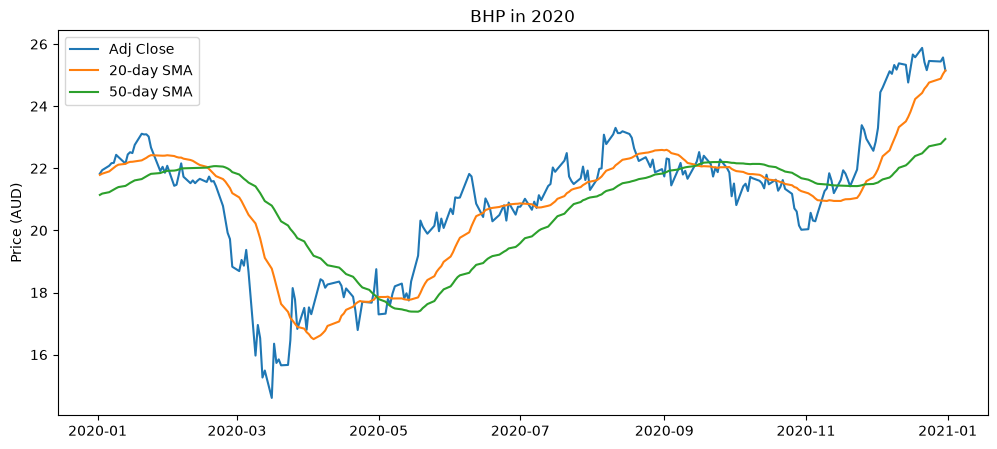

In [108]:
bhp_price_and_smas = plot_price_with_smas(bhp.loc["2020"], "BHP in 2020", currency="AUD")
bhp_price_and_smas

In [110]:
spy.loc['2020-01':'2020-03', 'Adj Close'].idxmax()

Timestamp('2020-02-19 00:00:00')

In [111]:
spy.loc['2020-02', 'Adj Close'].idxmax()

Timestamp('2020-02-19 00:00:00')

In [112]:
spy.loc["2020-02-24":"2020-03-10", ["Adj Close", "SMA_20", "SMA_50"]]

,Adj Close,SMA_20,SMA_50
Date,,,
2020-02-24,293.164093,301.355638,297.111702
2020-02-25,284.280548,300.862364,297.107485
2020-02-26,283.234894,300.162680,297.033315
2020-02-27,270.514435,298.839252,296.701299
2020-02-28,269.377930,297.410806,296.307104
2020-03-02,281.043579,296.836151,296.144953
2020-03-03,272.996765,295.750496,295.821503
2020-03-04,284.471527,295.013991,295.703846
2020-03-05,275.015167,293.631909,295.371601


In [117]:
f"{(spy.loc["2020-03-03", "Adj Close"] / spy.loc["2020-02-19", "Adj Close"] - 1):.2%}"

'-11.26%'

In [124]:
spy.loc['2020-03', 'Adj Close'].idxmin()

Timestamp('2020-03-23 00:00:00')

In [119]:
spy.loc["2020-04-24":"2020-05-10", ["Adj Close", "SMA_20", "SMA_50"]]

,Adj Close,SMA_20,SMA_50
Date,,,
2020-04-24,258.806763,246.941463,255.536419
2020-04-27,262.538330,248.479382,254.657673
2020-04-28,261.331024,249.580572,253.744959
2020-04-29,268.172211,251.202170,252.984892
2020-04-30,265.675385,253.229398,252.145609
2020-05-01,258.642120,254.645216,251.190938
2020-05-04,259.355408,256.263157,250.313635
2020-05-05,261.751709,257.238586,249.685387
2020-05-06,259.977356,258.112952,249.199323


In [125]:
f"{(spy.loc["2020-04-30", "Adj Close"] / spy.loc["2020-03-23", "Adj Close"] - 1):.2%}"

'30.29%'